# 02 — Apriori (association rules)

Category co-occurrence from paid orders + favorites per user.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from corevent_analytics.config import get_settings
from corevent_analytics.data import load_data, build_category_transactions
from corevent_analytics.models import run_apriori

sns.set_theme(style="whitegrid")
settings = get_settings()
tables, source = load_data(settings)
transactions = build_category_transactions(tables)
result = run_apriori(
    transactions,
    min_support=settings.min_support,
    min_confidence=settings.min_confidence,
)
print("source:", source, "| transactions:", result["n_transactions"])
result["frequent_itemsets"].head(20)

source: synthetic | transactions: 3000


,support,itemsets
0,0.199333,frozenset({music})
1,0.118333,frozenset({sports})
2,0.228000,frozenset({tech})
3,0.219000,frozenset({business})
4,0.226333,frozenset({education})
5,0.198333,frozenset({art_culture})
6,0.219000,frozenset({gastronomy})
7,0.116667,frozenset({health_wellness})
8,0.121000,frozenset({family_kids})
9,0.113000,frozenset({religious_spiritual})


In [2]:
rules = result["rules"]
rules.head(20)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,sports,family_kids,0.118333,0.121000,0.058000,0.490141,4.050751,1.0,0.043682,1.724006,0.854214,0.319853,0.419955,0.484740
1,family_kids,sports,0.121000,0.118333,0.058000,0.479339,4.050751,1.0,0.043682,1.693360,0.856806,0.319853,0.409458,0.484740
2,health_wellness,sports,0.116667,0.118333,0.054000,0.462857,3.911469,1.0,0.040194,1.641401,0.842651,0.298343,0.390764,0.459598
3,sports,health_wellness,0.118333,0.116667,0.054000,0.456338,3.911469,1.0,0.040194,1.624784,0.844244,0.298343,0.384534,0.459598
4,music,gastronomy,0.199333,0.219000,0.102667,0.515050,2.351827,1.0,0.059013,1.610476,0.717900,0.325238,0.379066,0.491924
5,gastronomy,music,0.219000,0.199333,0.102667,0.468798,2.351827,1.0,0.059013,1.507272,0.735978,0.325238,0.336550,0.491924
6,fashion_beauty,gastronomy,0.104667,0.219000,0.053333,0.509554,2.326731,1.0,0.030411,1.592429,0.636872,0.197287,0.372028,0.376543
7,health_wellness,community_social,0.116667,0.213667,0.058000,0.497143,2.326722,1.0,0.033072,1.563731,0.645522,0.212974,0.360504,0.384297
8,art_culture,music,0.198333,0.199333,0.091667,0.462185,2.318653,1.0,0.052132,1.488740,0.709416,0.299564,0.328291,0.461026
9,music,art_culture,0.199333,0.198333,0.091667,0.459866,2.318653,1.0,0.052132,1.484200,0.710302,0.299564,0.326236,0.461026


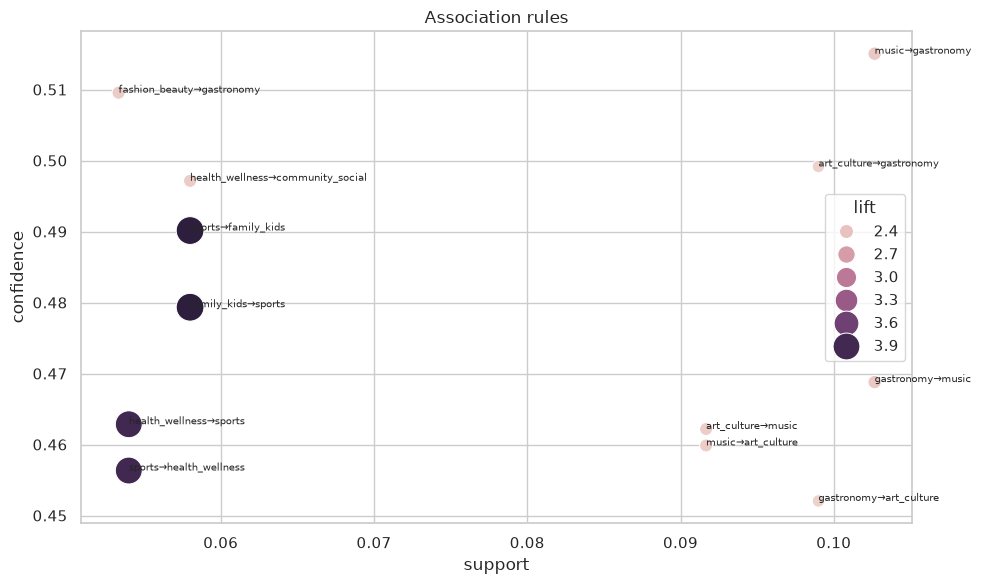

In [3]:
if rules.empty:
    print("No rules — try lowering MIN_SUPPORT / MIN_CONFIDENCE")
else:
    top = rules.head(12)
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.scatterplot(
        data=top,
        x="support",
        y="confidence",
        size="lift",
        hue="lift",
        sizes=(80, 400),
        ax=ax,
    )
    for _, row in top.iterrows():
        ax.text(row["support"], row["confidence"], f"{row['antecedents']}→{row['consequents']}", fontsize=7)
    ax.set_title("Association rules")
    fig.tight_layout()
    plt.show()